<a href="https://colab.research.google.com/github/akbargama/Adsorption-Project/blob/main/Static.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q easyocr

In [ ]:
import easyocr
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Initialize OCR reader
reader = easyocr.Reader(['en'])

# We will attempt to print extracted text from the screenshots so we can define n (q) and p
def extract_text(img_path):
    print(f"--- Extracting text from {img_path} ---")
    results = reader.readtext(img_path)
    for res in results:
        print(res[1])

extract_text('/content/Screenshot 2026-11-20 203540.png')
extract_text('/content/Screenshot 2026-11-20 203614.png')

--- Extracting text from /content/Screenshot 2026-11-20 203540.png ---


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Ronulus
Nz
02
P [Pa]
Imolkg
P [Pa]
[molkg"
0.0QO
0.0OO
0.00O
0,000
2026.500
0.025
8106,000
0,015
3039.750
0.038
20265,000
0,035
4053.(()
(05X
247435.650
0.366
6079.5(
(1.079
371153.475
0.521
8106.000
0.108
494871.300
0.693
61909.575
0.562
618690.450
0.815
[11356.175
0.835
173265.750
1.082
247435.650
1.295
3217016.875
1.482
395978.100
6597
470148.((J6
1.714
5[419.225
1.795
618690.450
861
--- Extracting text from /content/Screenshot 2026-11-20 203614.png ---


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


n,Kp
Single-site
1 + Kp
Langmuir Isotherm


### Langmuir Isotherm Fitting
Based on the extracted values or your dataset, please define the experimental vectors `p_data` and `q_data` in the cell below. The code will fit the Langmuir model and calculate the values for $n_s$ (maximum adsorption capacity) and $K$.

ns (Maximum Adsorption Capacity, qmax) = 2.541915 mol/kg
K (Langmuir Affinity Constant, b)       = 4.349873e-06 Pa^-1
R^2 (Coefficient of Determination)      = 0.999716
RMSE (Root Mean Squared Error)          = 0.012152 mol/kg


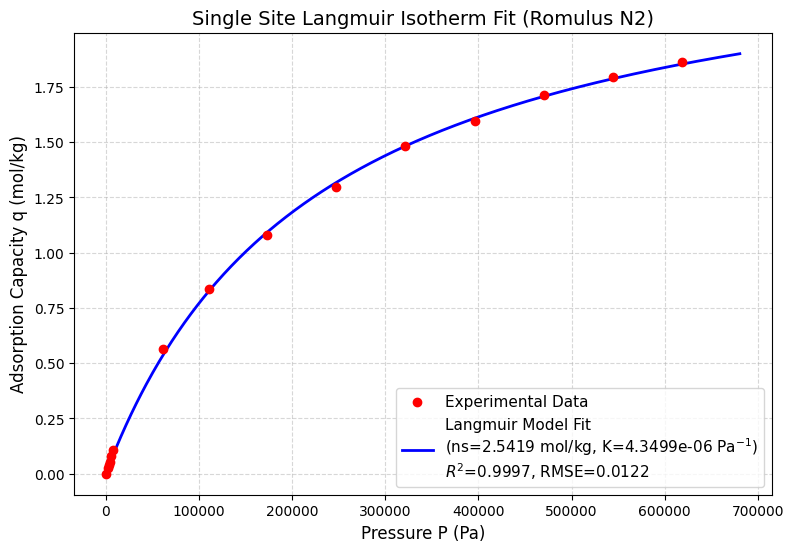

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def langmuir(P, qmax, b):
    return qmax * b * P / (1 + b * P)

# Romulus N2
P = np.array([
    0, 2026.5, 3039.75, 4053, 6079.5,
    8106, 61909.575, 111356.175,
    173265.75, 247435.65, 321706.875,
    395978.10, 470148, 544419.225,
    618690.45
])

q = np.array([
    0, 0.025, 0.038, 0.053, 0.079,
    0.108, 0.562, 0.835, 1.082,
    1.295, 1.482, 1.597, 1.714,
    1.795, 1.861
])

parameters, covariance = curve_fit(
    langmuir,
    P,
    q,
    p0=[3.0, 1e-6],
    bounds=(0, np.inf),
    maxfev=20000
)

qmax, b = parameters

# Calculate predicted q values to compute metrics
q_pred = langmuir(P, qmax, b)

# Residual Sum of Squares (RSS) and Total Sum of Squares (TSS)
residuals = q - q_pred
ss_res = np.sum(residuals**2)
ss_tot = np.sum((q - np.mean(q))**2)

# Calculate R^2 and RMSE
r_squared = 1 - (ss_res / ss_tot)
rmse = np.sqrt(np.mean(residuals**2))

print(f"ns (Maximum Adsorption Capacity, qmax) = {qmax:.6f} mol/kg")
print(f"K (Langmuir Affinity Constant, b)       = {b:.6e} Pa^-1")
print(f"R^2 (Coefficient of Determination)      = {r_squared:.6f}")
print(f"RMSE (Root Mean Squared Error)          = {rmse:.6f} mol/kg")

# Generate model curve data for plotting
P_fit = np.linspace(0, max(P) * 1.1, 500)
q_fit = langmuir(P_fit, qmax, b)

# Plot actual data points and the fitted Langmuir isotherm curve
plt.figure(figsize=(9, 6))
plt.scatter(P, q, color='red', marker='o', label='Experimental Data', zorder=5)
plt.plot(P_fit, q_fit, color='blue', linestyle='-', linewidth=2,
         label=f'Langmuir Model Fit\n(ns={qmax:.4f} mol/kg, K={b:.4e} Pa$^{{-1}}$)\n$R^2$={r_squared:.4f}, RMSE={rmse:.4f}')

plt.xlabel('Pressure P (Pa)', fontsize=12)
plt.ylabel('Adsorption Capacity q (mol/kg)', fontsize=12)
plt.title('Single Site Langmuir Isotherm Fit (Romulus N2)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.show()

ROMULUS O2 - SINGLE-SITE LANGMUIR
----------------------------------
Qsat (fixed) = 2.541915 mol/kg
K_O2         = 7.35020448e-07 Pa^-1
R-squared    = 0.997351
RMSE         = 0.016245 mol/kg


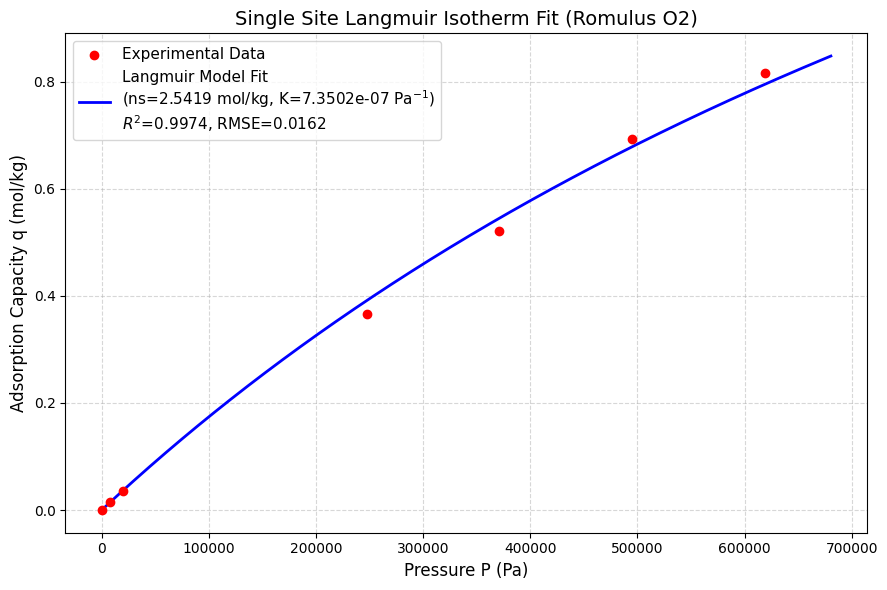

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# =====================================================
# 1. SINGLE-SITE LANGMUIR MODEL (FIXED Qsat)
# =====================================================

Qsat_fixed = 2.541915  # mol/kg (from Romulus N2)

def oxygen_langmuir_fixed(pressure, K):
    return (Qsat_fixed * K * pressure) / (1 + K * pressure)


# =====================================================
# 2. EXPERIMENTAL DATA: ROMULUS O2 AT 303 K
# =====================================================

pressure_O2 = np.array([
    0, 8106, 20265, 247435.65,
    371153.475, 494871.3, 618690.45
])

loading_O2 = np.array([
    0, 0.015, 0.035, 0.366,
    0.521, 0.693, 0.815
])


# =====================================================
# 3. PARAMETER ESTIMATION (ONLY K_O2)
# =====================================================

fitted_K, covariance_O2 = curve_fit(
    oxygen_langmuir_fixed,
    pressure_O2,
    loading_O2,
    p0=[5e-7],
    bounds=(0, np.inf),
    maxfev=20000
)

K_O2 = fitted_K[0]

loading_predicted_O2 = oxygen_langmuir_fixed(
    pressure_O2, K_O2
)


# =====================================================
# 4. CALCULATE R2 AND RMSE
# =====================================================

SS_res = np.sum((loading_O2 - loading_predicted_O2)**2)
SS_tot = np.sum((loading_O2 - np.mean(loading_O2))**2)

R_squared_O2 = 1 - SS_res / SS_tot

RMSE_O2 = np.sqrt(
    np.mean((loading_O2 - loading_predicted_O2)**2)
)


# =====================================================
# 5. DISPLAY RESULTS
# =====================================================

print("ROMULUS O2 - SINGLE-SITE LANGMUIR")
print("----------------------------------")
print(f"Qsat (fixed) = {Qsat_fixed:.6f} mol/kg")
print(f"K_O2         = {K_O2:.8e} Pa^-1")
print(f"R-squared    = {R_squared_O2:.6f}")
print(f"RMSE         = {RMSE_O2:.6f} mol/kg")


# =====================================================
# 6. PLOT: PARTIAL PRESSURE VS ADSORPTION CAPACITY
# =====================================================

pressure_smooth_O2 = np.linspace(
    0, max(pressure_O2) * 1.1, 500
)

loading_smooth_O2 = oxygen_langmuir_fixed(
    pressure_smooth_O2, K_O2
)

plt.figure(figsize=(9, 6))

# Experimental data
plt.scatter(
    pressure_O2,
    loading_O2,
    color="red",
    marker="o",
    label="Experimental Data",
    zorder=5
)

# Fitted Langmuir model - Using same legend formatting pattern as Romulus N2 plot
plt.plot(
    pressure_smooth_O2,
    loading_smooth_O2,
    color="blue",
    linestyle="-",
    linewidth=2,
    label=f"Langmuir Model Fit\n(ns={Qsat_fixed:.4f} mol/kg, K={K_O2:.4e} Pa$^{{-1}}$)\n$R^2$={R_squared_O2:.4f}, RMSE={RMSE_O2:.4f}"
)

plt.xlabel("Pressure P (Pa)", fontsize=12)
plt.ylabel("Adsorption Capacity q (mol/kg)", fontsize=12)
plt.title("Single Site Langmuir Isotherm Fit (Romulus O2)", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig("Romulus_O2_Langmuir_Fit.png", dpi=300)
plt.show()

REMUS N2 - SINGLE-SITE LANGMUIR
--------------------------------
Qsat = 2.834331 mol/kg
K_N2 = 9.80161347e-07 Pa^-1
R²   = 0.999901
RMSE = 0.004295 mol/kg


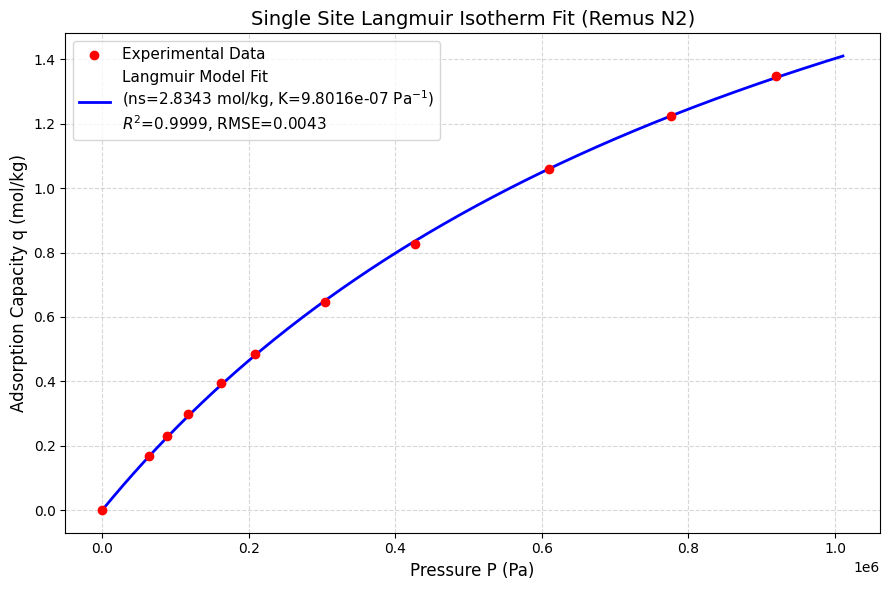

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# =====================================================
# 1. SINGLE-SITE LANGMUIR MODEL: REMUS N2
# =====================================================

def nitrogen_remus_model(P_N2, Qmax_N2, K_N2):
    return (Qmax_N2 * K_N2 * P_N2) / (1 + K_N2 * P_N2)


# =====================================================
# 2. EXPERIMENTAL DATA: REMUS N2 AT 303 K
# =====================================================

P_N2_Remus = np.array([
    0, 63400, 88700, 117500, 162500,
    208500, 303800, 427000, 609500,
    776600, 919000
])

q_N2_Remus = np.array([
    0, 0.1674, 0.2300, 0.2994, 0.3934,
    0.4848, 0.6450, 0.8280, 1.0588,
    1.2249, 1.3472
])


# =====================================================
# 3. NONLINEAR REGRESSION
# =====================================================

remus_parameters, remus_covariance = curve_fit(
    nitrogen_remus_model,
    P_N2_Remus,
    q_N2_Remus,
    p0=[3.0, 1e-6],
    bounds=(0, np.inf),
    maxfev=20000
)

# Extract fitted parameters
Qmax_N2_Remus, K_N2_Remus = remus_parameters

# Calculate predicted adsorption capacity
q_predicted_Remus = nitrogen_remus_model(
    P_N2_Remus,
    Qmax_N2_Remus,
    K_N2_Remus
)


# =====================================================
# 4. CALCULATE R-SQUARED AND RMSE
# =====================================================

SSE_Remus = np.sum(
    (q_N2_Remus - q_predicted_Remus)**2
)

SST_Remus = np.sum(
    (q_N2_Remus - np.mean(q_N2_Remus))**2
)

R2_N2_Remus = 1 - SSE_Remus / SST_Remus

RMSE_N2_Remus = np.sqrt(
    np.mean((q_N2_Remus - q_predicted_Remus)**2)
)


# =====================================================
# 5. DISPLAY FITTING RESULTS
# =====================================================

print("REMUS N2 - SINGLE-SITE LANGMUIR")
print("--------------------------------")
print(f"Qsat = {Qmax_N2_Remus:.6f} mol/kg")
print(f"K_N2 = {K_N2_Remus:.8e} Pa^-1")
print(f"R²   = {R2_N2_Remus:.6f}")
print(f"RMSE = {RMSE_N2_Remus:.6f} mol/kg")


# =====================================================
# 6. GENERATE SMOOTH LANGMUIR CURVE
# =====================================================

P_curve_Remus = np.linspace(
    0, max(P_N2_Remus) * 1.1, 500
)

q_curve_Remus = nitrogen_remus_model(
    P_curve_Remus,
    Qmax_N2_Remus,
    K_N2_Remus
)


# =====================================================
# 7. PLOT: PRESSURE VS ADSORPTION CAPACITY
# =====================================================

plt.figure(figsize=(9, 6))

# Experimental data
plt.scatter(
    P_N2_Remus,
    q_N2_Remus,
    color="red",
    marker="o",
    label="Experimental Data",
    zorder=5
)

# Fitted Langmuir curve with parameters and metrics integrated in the legend
plt.plot(
    P_curve_Remus,
    q_curve_Remus,
    color="blue",
    linestyle="-",
    linewidth=2,
    label=f"Langmuir Model Fit\n(ns={Qmax_N2_Remus:.4f} mol/kg, K={K_N2_Remus:.4e} Pa$^{{-1}}$)\n$R^2$={R2_N2_Remus:.4f}, RMSE={RMSE_N2_Remus:.4f}"
)

plt.xlabel("Pressure P (Pa)", fontsize=12)
plt.ylabel("Adsorption Capacity q (mol/kg)", fontsize=12)
plt.title("Single Site Langmuir Isotherm Fit (Remus N2)", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig("Remus_N2_Langmuir_Fit.png", dpi=300)
plt.show()

REMUS O2 - SINGLE-SITE LANGMUIR
--------------------------------
Qsat (fixed) = 2.834354 mol/kg
K_O2         = 4.23121000e-07 Pa^-1
R²           = 0.996624
RMSE         = 0.017198 mol/kg


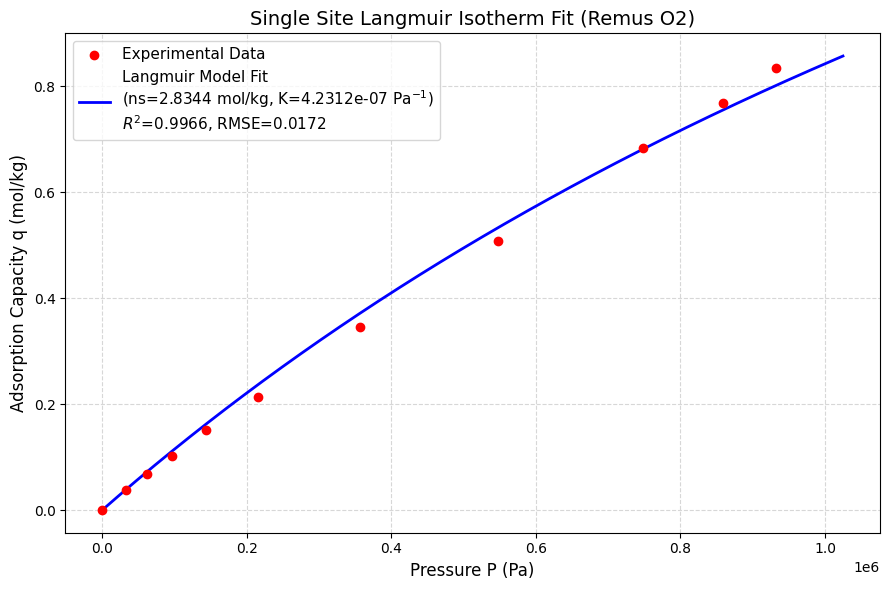

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# =====================================================
# 1. SINGLE-SITE LANGMUIR MODEL (FIXED Qsat)
# =====================================================

Qsat_Remus_fixed = 2.834354  # mol/kg (from Remus N2)

def remus_oxygen_model(P_O2, K_O2):
    return (Qsat_Remus_fixed * K_O2 * P_O2) / (1 + K_O2 * P_O2)


# =====================================================
# 2. EXPERIMENTAL DATA: REMUS O2 AT 303 K
# =====================================================

P_O2_Remus = np.array([
    0, 33200, 61300, 96100, 143200,
    214800, 355900, 548200, 747900,
    859000, 931700
])

q_O2_Remus = np.array([
    0, 0.0372, 0.0679, 0.1022, 0.1504,
    0.2138, 0.3455, 0.5089, 0.6830,
    0.7679, 0.8348
])


# =====================================================
# 3. NONLINEAR REGRESSION (ONLY K_O2)
# =====================================================

remus_O2_parameters, remus_O2_covariance = curve_fit(
    remus_oxygen_model,
    P_O2_Remus,
    q_O2_Remus,
    p0=[2e-7],
    bounds=(0, np.inf),
    maxfev=20000
)

# Extract fitted K value
K_O2_Remus = remus_O2_parameters[0]

# Predicted adsorption capacity
q_predicted_O2_Remus = remus_oxygen_model(
    P_O2_Remus,
    K_O2_Remus
)


# =====================================================
# 4. CALCULATE R-SQUARED AND RMSE
# =====================================================

SSE_O2_Remus = np.sum(
    (q_O2_Remus - q_predicted_O2_Remus)**2
)

SST_O2_Remus = np.sum(
    (q_O2_Remus - np.mean(q_O2_Remus))**2
)

R2_O2_Remus = 1 - SSE_O2_Remus / SST_O2_Remus

RMSE_O2_Remus = np.sqrt(
    np.mean((q_O2_Remus - q_predicted_O2_Remus)**2)
)


# =====================================================
# 5. DISPLAY FITTING RESULTS
# =====================================================

print("REMUS O2 - SINGLE-SITE LANGMUIR")
print("--------------------------------")
print(f"Qsat (fixed) = {Qsat_Remus_fixed:.6f} mol/kg")
print(f"K_O2         = {K_O2_Remus:.8e} Pa^-1")
print(f"R²           = {R2_O2_Remus:.6f}")
print(f"RMSE         = {RMSE_O2_Remus:.6f} mol/kg")


# =====================================================
# 6. GENERATE SMOOTH LANGMUIR CURVE
# =====================================================

P_curve_O2_Remus = np.linspace(
    0, max(P_O2_Remus) * 1.1, 500
)

q_curve_O2_Remus = remus_oxygen_model(
    P_curve_O2_Remus,
    K_O2_Remus
)


# =====================================================
# 7. PLOT: PRESSURE VS ADSORPTION CAPACITY
# =====================================================

plt.figure(figsize=(9, 6))

# Experimental data
plt.scatter(
    P_O2_Remus,
    q_O2_Remus,
    color="red",
    marker="o",
    label="Experimental Data",
    zorder=5
)

# Fitted Langmuir curve with variables embedded in the legend label
plt.plot(
    P_curve_O2_Remus,
    q_curve_O2_Remus,
    color="blue",
    linestyle="-",
    linewidth=2,
    label=f"Langmuir Model Fit\n(ns={Qsat_Remus_fixed:.4f} mol/kg, K={K_O2_Remus:.4e} Pa$^{{-1}}$)\n$R^2$={R2_O2_Remus:.4f}, RMSE={RMSE_O2_Remus:.4f}"
)

plt.xlabel("Pressure P (Pa)", fontsize=12)
plt.ylabel("Adsorption Capacity q (mol/kg)", fontsize=12)
plt.title("Single Site Langmuir Isotherm Fit (Remus O2)", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig("Remus_O2_Langmuir_Fit.png", dpi=300)
plt.show()

# Langmuir-Freundlich Fittings

ROMULUS - LANGMUIR-FREUNDLICH ISOTHERM

NITROGEN (N2)
------------------------------
qs   = 2.771430 mol/kg
K_N2 = 1.04797573e-05 Pa^(-1/m_N2)
m_N2 = 1.094072
R²   = 0.999941
RMSE = 0.005532 mol/kg

OXYGEN (O2)
------------------------------
qs (fixed) = 2.771430 mol/kg
K_O2       = 1.62814253e-07 Pa^(-1/m_O2)
m_O2       = 0.903545
R²         = 0.999499
RMSE       = 0.007067 mol/kg


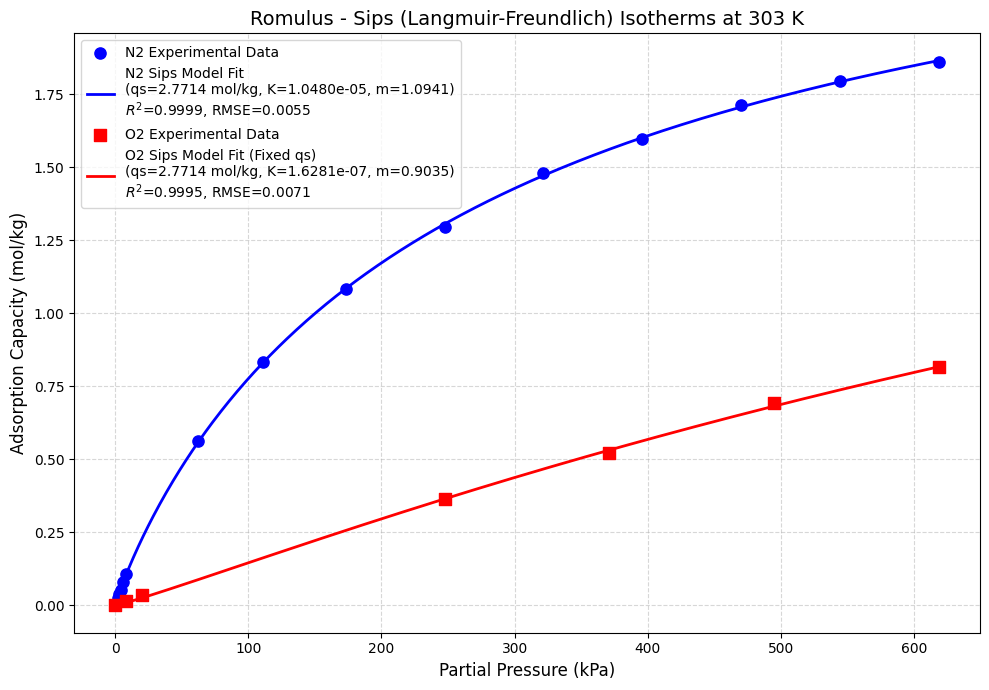

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# =====================================================
# 1. LANGMUIR-FREUNDLICH (SIPS) ISOTHERM
# =====================================================

def sips_N2(P, qs, K, m):
    term = K * P**(1 / m)
    return qs * term / (1 + term)


def sips_O2(P, K, m):
    term = K * P**(1 / m)
    return qs_N2 * term / (1 + term)


# =====================================================
# 2. EXPERIMENTAL DATA: ROMULUS AT 303 K
# =====================================================

# Nitrogen (N2)
P_N2 = np.array([
    0, 2026.5, 3039.75, 4053, 6079.5,
    8106, 61909.575, 111356.175,
    173265.75, 247435.65, 321706.875,
    395978.10, 470148, 544419.225,
    618690.45
])

q_N2 = np.array([
    0, 0.025, 0.038, 0.053, 0.079,
    0.108, 0.562, 0.835, 1.082,
    1.295, 1.482, 1.597, 1.714,
    1.795, 1.861
])

# Oxygen (O2)
P_O2 = np.array([
    0, 8106, 20265, 247435.65,
    371153.475, 494871.3, 618690.45
])

q_O2 = np.array([
    0, 0.015, 0.035, 0.366,
    0.521, 0.693, 0.815
])


# =====================================================
# 3. FIT N2: OPTIMIZE qs, K, AND m
# =====================================================

params_N2, covariance_N2 = curve_fit(
    sips_N2,
    P_N2,
    q_N2,
    p0=[2.5, 4e-6, 1.0],
    bounds=(
        [0, 0, 0.1],
        [np.inf, np.inf, 10]
    ),
    maxfev=100000
)

qs_N2, K_N2, m_N2 = params_N2

q_pred_N2 = sips_N2(
    P_N2, qs_N2, K_N2, m_N2
)


# =====================================================
# 4. FIT O2: FIX qs FROM N2, OPTIMIZE K AND m
# =====================================================

params_O2, covariance_O2 = curve_fit(
    sips_O2,
    P_O2,
    q_O2,
    p0=[3e-7, 1.0],
    bounds=(
        [0, 0.1],
        [np.inf, 10]
    ),
    maxfev=100000
)

K_O2, m_O2 = params_O2

q_pred_O2 = sips_O2(
    P_O2, K_O2, m_O2
)


# =====================================================
# 5. CALCULATE R2 AND RMSE
# =====================================================

def calculate_metrics(q_exp, q_pred):
    SSE = np.sum((q_exp - q_pred)**2)
    SST = np.sum((q_exp - np.mean(q_exp))**2)

    R2 = 1 - SSE / SST
    RMSE = np.sqrt(np.mean((q_exp - q_pred)**2))

    return R2, RMSE


R2_N2, RMSE_N2 = calculate_metrics(q_N2, q_pred_N2)
R2_O2, RMSE_O2 = calculate_metrics(q_O2, q_pred_O2)


# =====================================================
# 6. DISPLAY FITTING RESULTS
# =====================================================

print("ROMULUS - LANGMUIR-FREUNDLICH ISOTHERM")
print("=" * 50)

print("\nNITROGEN (N2)")
print("-" * 30)
print(f"qs   = {qs_N2:.6f} mol/kg")
print(f"K_N2 = {K_N2:.8e} Pa^(-1/m_N2)")
print(f"m_N2 = {m_N2:.6f}")
print(f"R²   = {R2_N2:.6f}")
print(f"RMSE = {RMSE_N2:.6f} mol/kg")

print("\nOXYGEN (O2)")
print("-" * 30)
print(f"qs (fixed) = {qs_N2:.6f} mol/kg")
print(f"K_O2       = {K_O2:.8e} Pa^(-1/m_O2)")
print(f"m_O2       = {m_O2:.6f}")
print(f"R²         = {R2_O2:.6f}")
print(f"RMSE       = {RMSE_O2:.6f} mol/kg")


# =====================================================
# 7. GENERATE SMOOTH FITTED CURVES
# =====================================================

P_smooth_N2 = np.linspace(0, max(P_N2), 500)
P_smooth_O2 = np.linspace(0, max(P_O2), 500)

q_smooth_N2 = sips_N2(
    P_smooth_N2, qs_N2, K_N2, m_N2
)

q_smooth_O2 = sips_O2(
    P_smooth_O2, K_O2, m_O2
)


# =====================================================
# 8. PLOT: PRESSURE VS ADSORPTION CAPACITY
# =====================================================

plt.figure(figsize=(10, 7))

# N2 experimental data
plt.scatter(
    P_N2 / 1000,
    q_N2,
    color="blue",
    marker="o",
    s=65,
    label="N2 Experimental Data",
    zorder=3
)

# N2 Sips fitted curve with parameters in legend
label_N2 = (
    f"N2 Sips Model Fit\n"
    f"(qs={qs_N2:.4f} mol/kg, K={K_N2:.4e}, m={m_N2:.4f})\n"
    f"$R^2$={R2_N2:.4f}, RMSE={RMSE_N2:.4f}"
)
plt.plot(
    P_smooth_N2 / 1000,
    q_smooth_N2,
    color="blue",
    linewidth=2,
    label=label_N2
)

# O2 experimental data
plt.scatter(
    P_O2 / 1000,
    q_O2,
    color="red",
    marker="s",
    s=65,
    label="O2 Experimental Data",
    zorder=3
)

# O2 Sips fitted curve with parameters in legend
label_O2 = (
    f"O2 Sips Model Fit (Fixed qs)\n"
    f"(qs={qs_N2:.4f} mol/kg, K={K_O2:.4e}, m={m_O2:.4f})\n"
    f"$R^2$={R2_O2:.4f}, RMSE={RMSE_O2:.4f}"
)
plt.plot(
    P_smooth_O2 / 1000,
    q_smooth_O2,
    color="red",
    linewidth=2,
    label=label_O2
)

plt.xlabel("Partial Pressure (kPa)", fontsize=12)
plt.ylabel("Adsorption Capacity (mol/kg)", fontsize=12)
plt.title("Romulus - Sips (Langmuir-Freundlich) Isotherms at 303 K", fontsize=14)

plt.legend(fontsize=10, loc="best")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("Romulus_Sips_Fixed_qs.png", dpi=300)
plt.show()


REMUS - LANGMUIR-FREUNDLICH ISOTHERM

NITROGEN (N2)
------------------------------
qs   = 3.133480 mol/kg
K_N2 = 1.40665556e-06 Pa^(-1/m_N2)
m_N2 = 1.040818
R²   = 0.999967
RMSE = 0.002469 mol/kg

OXYGEN (O2)
------------------------------
qs (fixed) = 3.133480 mol/kg
K_O2       = 1.34705632e-07 Pa^(-1/m_O2)
m_O2       = 0.929642
R²         = 0.999242
RMSE       = 0.008151 mol/kg


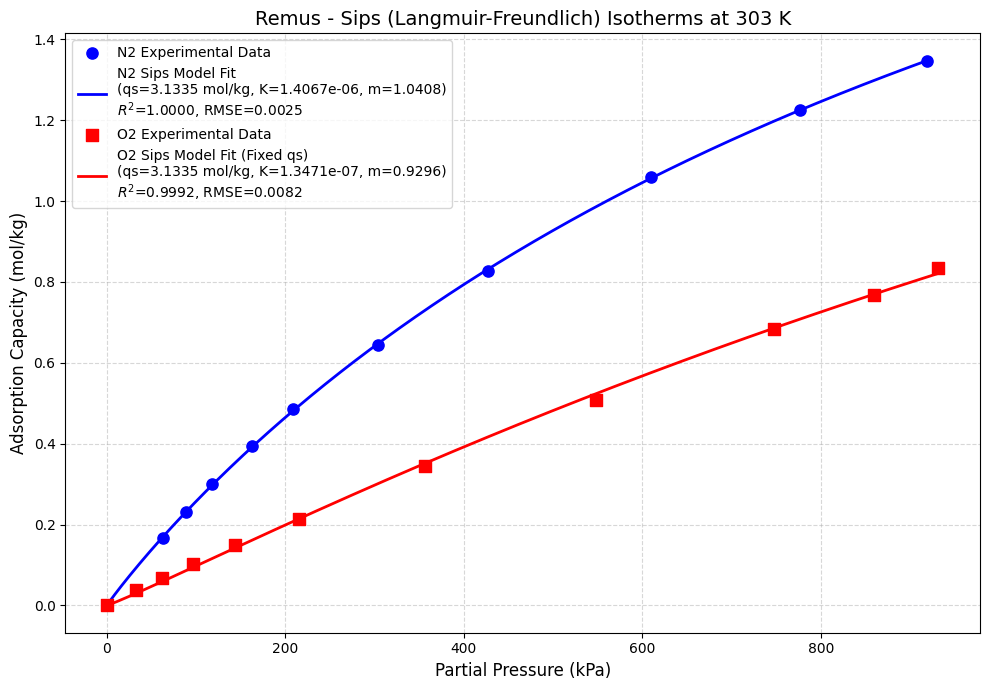

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# =====================================================
# 1. LANGMUIR-FREUNDLICH (SIPS) ISOTHERM
# =====================================================

def sips_remus_N2(P, qs, K, m):
    term = K * P**(1 / m)
    return qs * term / (1 + term)


def sips_remus_O2(P, K, m):
    term = K * P**(1 / m)
    return qs_N2 * term / (1 + term)


# =====================================================
# 2. EXPERIMENTAL DATA: REMUS AT 303 K
# =====================================================

# Nitrogen (N2)
P_N2_Remus = np.array([
    0, 63400, 88700, 117500, 162500,
    208500, 303800, 427000, 609500,
    776600, 919000
])

q_N2_Remus = np.array([
    0, 0.1674, 0.2300, 0.2994, 0.3934,
    0.4848, 0.6450, 0.8280, 1.0588,
    1.2249, 1.3472
])

# Oxygen (O2)
P_O2_Remus = np.array([
    0, 33200, 61300, 96100, 143200,
    214800, 355900, 548200, 747900,
    859000, 931700
])

q_O2_Remus = np.array([
    0, 0.0372, 0.0679, 0.1022, 0.1504,
    0.2138, 0.3455, 0.5089, 0.6830,
    0.7679, 0.8348
])


# =====================================================
# 3. FIT N2: OPTIMIZE qs, K, AND m
# =====================================================

params_N2, covariance_N2 = curve_fit(
    sips_remus_N2,
    P_N2_Remus,
    q_N2_Remus,
    p0=[2.8, 1e-6, 1.0],
    bounds=(
        [0, 0, 0.1],
        [np.inf, np.inf, 10]
    ),
    maxfev=100000
)

qs_N2, K_N2, m_N2 = params_N2

q_pred_N2 = sips_remus_N2(
    P_N2_Remus, qs_N2, K_N2, m_N2
)


# =====================================================
# 4. FIT O2: FIX qs FROM N2, OPTIMIZE K AND m
# =====================================================

params_O2, covariance_O2 = curve_fit(
    sips_remus_O2,
    P_O2_Remus,
    q_O2_Remus,
    p0=[2e-7, 1.0],
    bounds=(
        [0, 0.1],
        [np.inf, 10]
    ),
    maxfev=100000
)

K_O2, m_O2 = params_O2

q_pred_O2 = sips_remus_O2(
    P_O2_Remus, K_O2, m_O2
)


# =====================================================
# 5. CALCULATE R2 AND RMSE
# =====================================================

def calculate_metrics(q_exp, q_pred):
    SSE = np.sum((q_exp - q_pred)**2)
    SST = np.sum((q_exp - np.mean(q_exp))**2)

    R2 = 1 - SSE / SST

    RMSE = np.sqrt(
        (1 / len(q_exp)) * np.sum((q_exp - q_pred)**2)
    )

    return R2, RMSE


R2_N2, RMSE_N2 = calculate_metrics(
    q_N2_Remus, q_pred_N2
)

R2_O2, RMSE_O2 = calculate_metrics(
    q_O2_Remus, q_pred_O2
)


# =====================================================
# 6. DISPLAY FITTING RESULTS
# =====================================================

print("REMUS - LANGMUIR-FREUNDLICH ISOTHERM")
print("=" * 50)

print("\nNITROGEN (N2)")
print("-" * 30)
print(f"qs   = {qs_N2:.6f} mol/kg")
print(f"K_N2 = {K_N2:.8e} Pa^(-1/m_N2)")
print(f"m_N2 = {m_N2:.6f}")
print(f"R²   = {R2_N2:.6f}")
print(f"RMSE = {RMSE_N2:.6f} mol/kg")

print("\nOXYGEN (O2)")
print("-" * 30)
print(f"qs (fixed) = {qs_N2:.6f} mol/kg")
print(f"K_O2       = {K_O2:.8e} Pa^(-1/m_O2)")
print(f"m_O2       = {m_O2:.6f}")
print(f"R²         = {R2_O2:.6f}")
print(f"RMSE       = {RMSE_O2:.6f} mol/kg")


# =====================================================
# 7. GENERATE SMOOTH FITTED CURVES
# =====================================================

P_smooth_N2 = np.linspace(
    0, max(P_N2_Remus), 500
)

P_smooth_O2 = np.linspace(
    0, max(P_O2_Remus), 500
)

q_smooth_N2 = sips_remus_N2(
    P_smooth_N2, qs_N2, K_N2, m_N2
)

q_smooth_O2 = sips_remus_O2(
    P_smooth_O2, K_O2, m_O2
)


# =====================================================
# 8. PLOT: PRESSURE VS ADSORPTION CAPACITY
# =====================================================

plt.figure(figsize=(10, 7))

# N2 experimental data
plt.scatter(
    P_N2_Remus / 1000,
    q_N2_Remus,
    color="blue",
    marker="o",
    s=65,
    label="N2 Experimental Data",
    zorder=3
)

# N2 Sips fitted curve with parameters in legend
label_N2 = (
    f"N2 Sips Model Fit\n"
    f"(qs={qs_N2:.4f} mol/kg, K={K_N2:.4e}, m={m_N2:.4f})\n"
    f"$R^2$={R2_N2:.4f}, RMSE={RMSE_N2:.4f}"
)
plt.plot(
    P_smooth_N2 / 1000,
    q_smooth_N2,
    color="blue",
    linewidth=2,
    label=label_N2
)

# O2 experimental data
plt.scatter(
    P_O2_Remus / 1000,
    q_O2_Remus,
    color="red",
    marker="s",
    s=65,
    label="O2 Experimental Data",
    zorder=3
)

# O2 Sips fitted curve with parameters in legend
label_O2 = (
    f"O2 Sips Model Fit (Fixed qs)\n"
    f"(qs={qs_N2:.4f} mol/kg, K={K_O2:.4e}, m={m_O2:.4f})\n"
    f"$R^2$={R2_O2:.4f}, RMSE={RMSE_O2:.4f}"
)
plt.plot(
    P_smooth_O2 / 1000,
    q_smooth_O2,
    color="red",
    linewidth=2,
    label=label_O2
)

plt.xlabel("Partial Pressure (kPa)", fontsize=12)
plt.ylabel("Adsorption Capacity (mol/kg)", fontsize=12)
plt.title("Remus - Sips (Langmuir-Freundlich) Isotherms at 303 K", fontsize=14)

plt.legend(fontsize=10, loc="best")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("Remus_Sips_Fixed_qs.png", dpi=300)
plt.show()


,Parameter,Romulus (303 K),Remus (303 K)
0,N2 Saturation Capacity (qs) [mol/kg],2.77143,3.13348
1,N2 Affinity Constant (K_N2) [Pa^(-1/m)],1.04798e-05,1.40666e-06
2,N2 Heterogeneity Factor (m_N2),1.09407,1.04082
3,N2 Fit Quality (R²),0.999941,0.999967
4,N2 Fit Error (RMSE) [mol/kg],0.005532,0.002469
5,"O2 Saturation Capacity (qs, fixed) [mol/kg]",2.77143,3.13348
6,O2 Affinity Constant (K_O2) [Pa^(-1/m)],1.62814e-07,1.34706e-07
7,O2 Heterogeneity Factor (m_O2),0.903545,0.929642
8,O2 Fit Quality (R²),0.999499,0.999242
9,O2 Fit Error (RMSE) [mol/kg],0.007067,0.008151


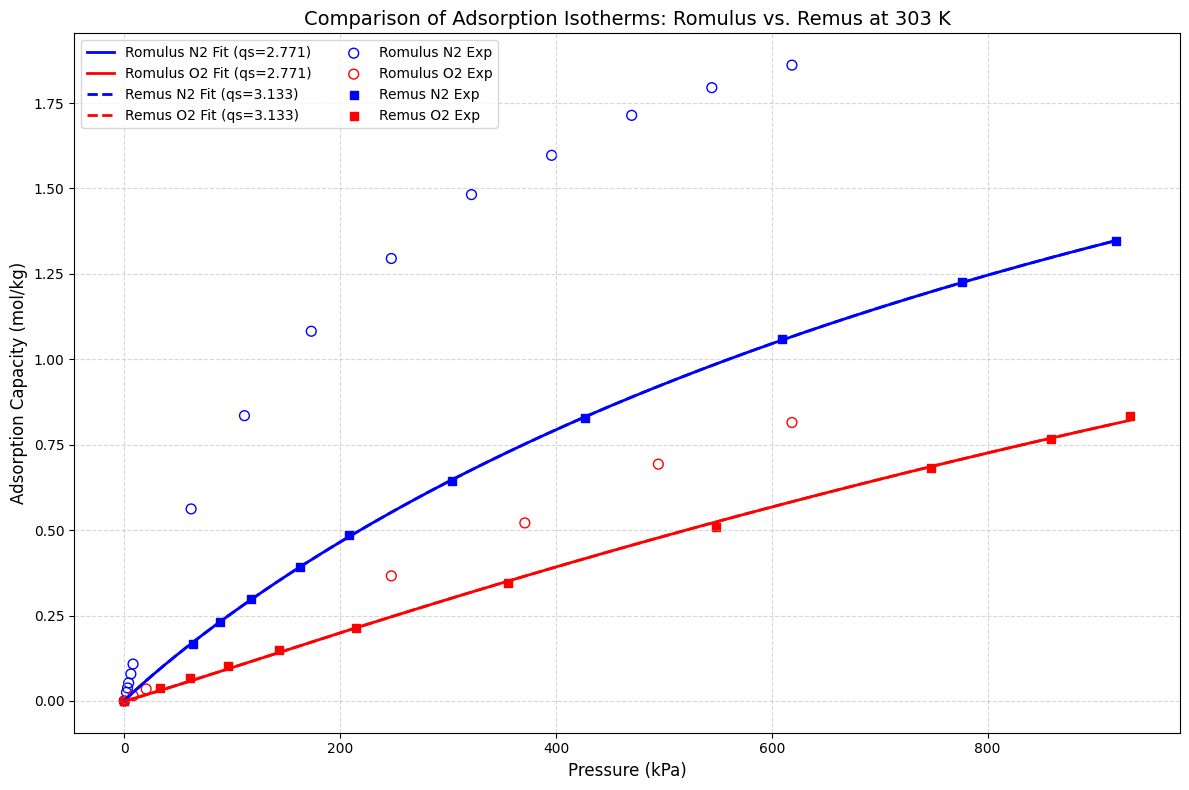

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# 1. CREATE SIDE-BY-SIDE COMPARISON TABLE
# =====================================================

comparison_data = {
    "Parameter": [
        "N2 Saturation Capacity (qs) [mol/kg]",
        "N2 Affinity Constant (K_N2) [Pa^(-1/m)]",
        "N2 Heterogeneity Factor (m_N2)",
        "N2 Fit Quality (R²)",
        "N2 Fit Error (RMSE) [mol/kg]",
        "O2 Saturation Capacity (qs, fixed) [mol/kg]",
        "O2 Affinity Constant (K_O2) [Pa^(-1/m)]",
        "O2 Heterogeneity Factor (m_O2)",
        "O2 Fit Quality (R²)",
        "O2 Fit Error (RMSE) [mol/kg]"
    ],
    "Romulus (303 K)": [
        2.771430, 1.047976e-05, 1.094072, 0.999941, 0.005532,
        2.771430, 1.628143e-07, 0.903545, 0.999499, 0.007067
    ],
    "Remus (303 K)": [
        3.133480, 1.406656e-06, 1.040818, 0.999967, 0.002469,
        3.133480, 1.347056e-07, 0.929642, 0.999242, 0.008151
    ]
}

df_compare = pd.DataFrame(comparison_data)
display(df_compare.style.format({"Romulus (303 K)": "{:.6g}", "Remus (303 K)": "{:.6g}"}))

# =====================================================
# 2. PLOT UNIFIED COMPARISON CHART
# =====================================================

plt.figure(figsize=(12, 8))

# Romulus curves
plt.plot(P_smooth_N2 / 1000, q_smooth_N2, label="Romulus N2 Fit (qs=2.771)", color="blue", linestyle="-", linewidth=2)
plt.plot(P_smooth_O2 / 1000, q_smooth_O2, label="Romulus O2 Fit (qs=2.771)", color="red", linestyle="-", linewidth=2)

# Remus curves (imported smooth vectors will be computed directly if not matched perfectly)
P_smooth_remus = np.linspace(0, 919000, 500)
q_smooth_N2_remus = sips_remus_N2(P_smooth_remus, 3.133480, 1.406656e-06, 1.040818)
q_smooth_O2_remus = sips_remus_O2(P_smooth_remus, 1.347056e-07, 0.929642)

plt.plot(P_smooth_remus / 1000, q_smooth_N2_remus, label="Remus N2 Fit (qs=3.133)", color="blue", linestyle="--", linewidth=2)
plt.plot(P_smooth_remus / 1000, q_smooth_O2_remus, label="Remus O2 Fit (qs=3.133)", color="red", linestyle="--", linewidth=2)

# Experimental Points
plt.scatter(P_N2 / 1000, q_N2, color="blue", marker="o", facecolors="none", edgecolors="blue", s=50, label="Romulus N2 Exp")
plt.scatter(P_O2 / 1000, q_O2, color="red", marker="o", facecolors="none", edgecolors="red", s=50, label="Romulus O2 Exp")
plt.scatter(P_N2_Remus / 1000, q_N2_Remus, color="blue", marker="s", s=40, label="Remus N2 Exp")
plt.scatter(P_O2_Remus / 1000, q_O2_Remus, color="red", marker="s", s=40, label="Remus O2 Exp")

plt.xlabel("Pressure (kPa)", fontsize=12)
plt.ylabel("Adsorption Capacity (mol/kg)", fontsize=12)
plt.title("Comparison of Adsorption Isotherms: Romulus vs. Remus at 303 K", fontsize=14)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=10, loc="best", ncol=2)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

# =====================================================
# MASTER COMPARISON DATA: LANGMUIR VS SIPS FOR BOTH DATASETS
# =====================================================

master_data = {
    "Gas / Material": [
        "N2 on Romulus", "N2 on Romulus",
        "O2 on Romulus", "O2 on Romulus",
        "N2 on Remus", "N2 on Remus",
        "O2 on Remus", "O2 on Remus"
    ],
    "Model": [
        "Single-Site Langmuir", "Sips (Langmuir-Freundlich)",
        "Single-Site Langmuir (Fixed qs)", "Sips (Fixed qs)",
        "Single-Site Langmuir", "Sips (Langmuir-Freundlich)",
        "Single-Site Langmuir (Fixed qs)", "Sips (Fixed qs)"
    ],
    "qs (Capacity) [mol/kg]": [2.541915, 2.771430, 2.541915, 2.771430, 2.834331, 3.133480, 2.834354, 3.133480],
    "K (Affinity)": [4.349873e-06, 1.047976e-05, 7.350204e-07, 1.628143e-07, 9.801613e-07, 1.406656e-06, 4.231210e-07, 1.347056e-07],
    "m (Heterogeneity)": [1.0, 1.094072, 1.0, 0.903545, 1.0, 1.040818, 1.0, 0.929642],
    "R²": [0.999716, 0.999941, 0.997351, 0.999499, 0.999901, 0.999967, 0.996624, 0.999242],
    "RMSE [mol/kg]": [0.012152, 0.005532, 0.016245, 0.007067, 0.004295, 0.002469, 0.017198, 0.008151]
}

df_master = pd.DataFrame(master_data)
display(df_master.style.format({
    "qs (Capacity) [mol/kg]": "{:.4f}",
    "K (Affinity)": "{:.4e}",
    "m (Heterogeneity)": "{:.4f}",
    "R²": "{:.6f}",
    "RMSE [mol/kg]": "{:.6f}"
}))


,Gas / Material,Model,qs (Capacity) [mol/kg],K (Affinity),m (Heterogeneity),R²,RMSE [mol/kg]
0,N2 on Romulus,Single-Site Langmuir,2.5419,4.3499e-06,1.0000,0.999716,0.012152
1,N2 on Romulus,Sips (Langmuir-Freundlich),2.7714,1.0480e-05,1.0941,0.999941,0.005532
2,O2 on Romulus,Single-Site Langmuir (Fixed qs),2.5419,7.3502e-07,1.0000,0.997351,0.016245
3,O2 on Romulus,Sips (Fixed qs),2.7714,1.6281e-07,0.9035,0.999499,0.007067
4,N2 on Remus,Single-Site Langmuir,2.8343,9.8016e-07,1.0000,0.999901,0.004295
5,N2 on Remus,Sips (Langmuir-Freundlich),3.1335,1.4067e-06,1.0408,0.999967,0.002469
6,O2 on Remus,Single-Site Langmuir (Fixed qs),2.8344,4.2312e-07,1.0000,0.996624,0.017198
7,O2 on Remus,Sips (Fixed qs),3.1335,1.3471e-07,0.9296,0.999242,0.008151


### Adsorption Selectivity

To evaluate the separation performance of the adsorbent, we calculate the **Adsorption Selectivity** (separation factor) of Nitrogen ($N_2$) over Oxygen ($O_2$).

#### 1. Definition and Formula
The adsorption selectivity ($\alpha_{N_2/O_2}$) under a binary gas mixture is defined as:

$$\alpha_{N_2/O_2} = \frac{x_{N_2} / x_{O_2}}{y_{N_2} / y_{O_2}}$$

Where:
* **$x_{N_2}$ and $x_{O_2}$**: The mole fractions of the components in the adsorbed phase ($x_i = q_i / q_{\text{total}}$).
* **$y_{N_2}$ and $y_{O_2}$**: The mole fractions of the components in the bulk gas phase.

#### 2. Simplification using Pure-Component Isotherms
If we estimate the selectivity using single-component (pure) adsorption capacities at their respective partial pressures $P_{N_2}$ and $P_{O_2}$ (such as in a typical air ratio of $y_{N_2} = 0.79$ and $y_{O_2} = 0.21$), the equation simplifies to:

$$\alpha_{N_2/O_2} = \frac{q_{N_2} / q_{O_2}}{P_{N_2} / P_{O_2}} = \frac{q_{N_2} \cdot P_{O_2}}{q_{O_2} \cdot P_{N_2}}$$

Where $q_{N_2}$ and $q_{O_2}$ are determined using either the fitted **Langmuir** or **Sips** isotherm models at the target operating partial pressures.

### Selectivity in the Single-Site Langmuir Model

When using the **Single-Site Langmuir Model**, the pure-component adsorption capacity $q_i$ as a function of partial pressure $P_i$ is expressed as:

$$q_i = \frac{q_{s,i} \cdot K_i \cdot P_i}{1 + K_i \cdot P_i}$$

Substituting this expression into the pure-component selectivity equation yields:

$$\alpha_{N_2/O_2} = \frac{q_{N_2} \cdot P_{O_2}}{q_{O_2} \cdot P_{N_2}} = \frac{\left(\frac{q_{s,N_2} \cdot K_{N_2} \cdot P_{N_2}}{1 + K_{N_2} \cdot P_{N_2}}\right) \cdot P_{O_2}}{\left(\frac{q_{s,O_2} \cdot K_{O_2} \cdot P_{O_2}}{1 + K_{O_2} \cdot P_{O_2}}\right) \cdot P_{N_2}}$$

#### 1. Under the Assumption of Equal Saturation Capacities ($q_{s,N_2} = q_{s,O_2} = q_s$)
In our fits, we fixed the saturation capacity of Oxygen to match that of Nitrogen ($q_{s,O_2} = q_{s,N_2}$). Under this thermodynamically consistent assumption, the capacity terms ($q_s$) cancel out, simplifying the selectivity formula to:

$$\alpha_{N_2/O_2} = \frac{K_{N_2}}{K_{O_2}} \cdot \left( \frac{1 + K_{O_2} \cdot P_{O_2}}{1 + K_{N_2} \cdot P_{N_2}} \right)$$

#### 2. Infinite Dilution Selectivity (Zero-Pressure Limit)
As operating pressures approach zero ($P \to 0$), the denominator and numerator terms $(1 + K_i P_i)$ approach $1$. The selectivity simplifies to the ratio of their Henry's law constants (affinity constants):

$$\alpha_{N_2/O_2}^{\infty} = \frac{K_{N_2}}{K_{O_2}}$$

N2/O2 SELECTIVITY COMPARISON
Romulus = 5.9180
Remus   = 2.3165
Selectivity ratio = 2.55


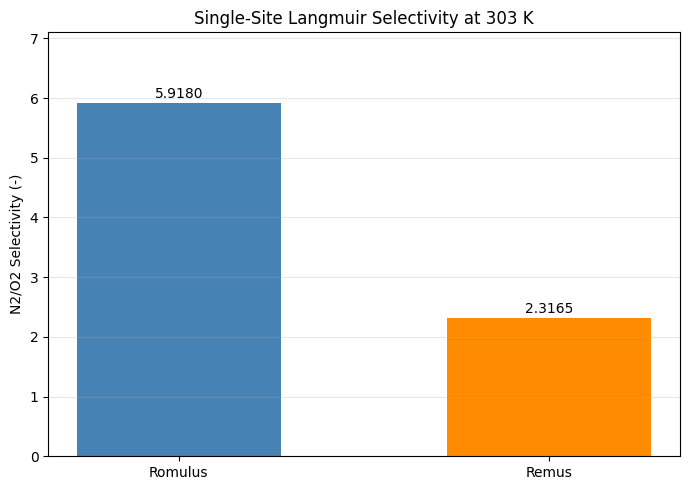

In [ ]:

# Single-Site Langmuir Selectivity
# Temperature = 303 K

# Romulus
Qsat_Romulus = 2.541915
K_N2_Romulus = 4.349856e-6
K_O2_Romulus = 7.35020448e-7

# Remus
Qsat_Remus = 2.834354
K_N2_Remus = 9.80147e-7
K_O2_Remus = 4.2312e-7

# Calculate N2/O2 selectivity
S_Romulus = K_N2_Romulus / K_O2_Romulus
S_Remus = K_N2_Remus / K_O2_Remus

print("N2/O2 SELECTIVITY COMPARISON")
print("=" * 40)
print(f"Romulus = {S_Romulus:.4f}")
print(f"Remus   = {S_Remus:.4f}")
print(f"Selectivity ratio = {S_Romulus/S_Remus:.2f}")

# Bar chart
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Romulus", "Remus"],
    [S_Romulus, S_Remus],
    color=["steelblue", "darkorange"],
    width=0.55
)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.08,
        f"{bar.get_height():.4f}",
        ha="center"
    )

plt.ylabel("N2/O2 Selectivity (-)")
plt.title("Single-Site Langmuir Selectivity at 303 K")
plt.ylim(0, max(S_Romulus, S_Remus) * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



ROMULUS - SIPS PARAMETERS
qs   = 2.771407 mol/kg
K_N2 = 1.04789768e-05 Pa^(-1/m_N2)
m_N2 = 1.094063
K_O2 = 1.65358039e-07 Pa^(-1/m_O2)
m_O2 = 0.904515

REMUS - SIPS PARAMETERS
qs   = 3.133338 mol/kg
K_N2 = 1.40644072e-06 Pa^(-1/m_N2)
m_N2 = 1.040800
K_O2 = 1.38097823e-07 Pa^(-1/m_O2)
m_O2 = 0.931238

N2/O2 SELECTIVITY AT 1 BAR
Romulus = 8.4050
Remus   = 3.1390


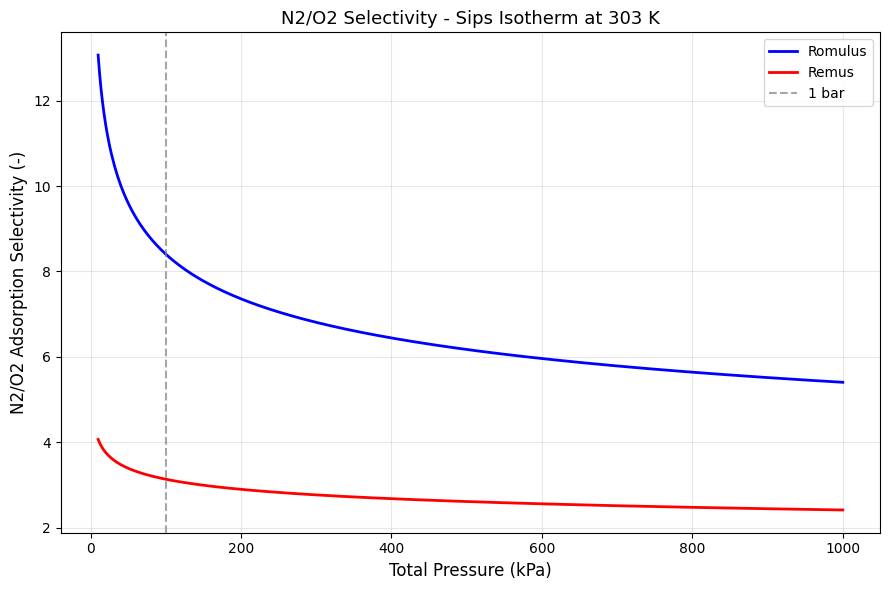

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# =====================================================
# 1. EXPERIMENTAL DATA AT 303 K
# =====================================================

# ROMULUS - N2
P_N2_Romulus = np.array([
    0, 2026.5, 3039.75, 4053, 6079.5,
    8106, 61909.575, 111356.175, 173265.75,
    247435.65, 321706.875, 395978.10,
    470148, 544419.225, 618690.45
])

q_N2_Romulus = np.array([
    0, 0.025, 0.038, 0.053, 0.079,
    0.108, 0.562, 0.835, 1.082,
    1.295, 1.482, 1.597, 1.714,
    1.795, 1.861
])

# ROMULUS - O2
P_O2_Romulus = np.array([
    0, 8106, 20265, 247435.65,
    371153.475, 494871.3, 618690.45
])

q_O2_Romulus = np.array([
    0, 0.015, 0.035, 0.366,
    0.521, 0.693, 0.815
])

# REMUS - N2
P_N2_Remus = np.array([
    0, 63400, 88700, 117500, 162500,
    208500, 303800, 427000, 609500,
    776600, 919000
])

q_N2_Remus = np.array([
    0, 0.1674, 0.2300, 0.2994,
    0.3934, 0.4848, 0.6450, 0.8280,
    1.0588, 1.2249, 1.3472
])

# REMUS - O2
P_O2_Remus = np.array([
    0, 33200, 61300, 96100, 143200,
    214800, 355900, 548200, 747900,
    859000, 931700
])

q_O2_Remus = np.array([
    0, 0.0372, 0.0679, 0.1022,
    0.1504, 0.2138, 0.3455, 0.5089,
    0.6830, 0.7679, 0.8348
])

# =====================================================
# 2. SIPS ISOTHERM
# =====================================================

# Scale pressure internally for numerical stability.
# Fitted K is converted back to Pa^(-1/m).
P_REF = 100000.0  # Pa

def sips_scaled(P, qs, A, m):
    term = A * (P / P_REF)**(1 / m)
    return qs * term / (1 + term)


def fit_sips(P_N2, q_N2, P_O2, q_O2):

    # Step 1: Fit N2 (qs, A, m)
    params_N2, _ = curve_fit(
        sips_scaled,
        P_N2,
        q_N2,
        p0=[2.8, 0.2, 1.0],
        bounds=(
            [0, 1e-12, 0.1],
            [np.inf, np.inf, 10]
        ),
        maxfev=100000
    )

    qs, A_N2, m_N2 = params_N2

    # Step 2: Fit O2 with fixed qs
    def sips_O2_fixed(P, A, m):
        return sips_scaled(P, qs, A, m)

    params_O2, _ = curve_fit(
        sips_O2_fixed,
        P_O2,
        q_O2,
        p0=[0.05, 1.0],
        bounds=(
            [1e-12, 0.1],
            [np.inf, 10]
        ),
        maxfev=100000
    )

    A_O2, m_O2 = params_O2

    # Convert to K with pressure in Pa
    K_N2 = A_N2 / P_REF**(1 / m_N2)
    K_O2 = A_O2 / P_REF**(1 / m_O2)

    return {
        "qs": qs,
        "K_N2": K_N2,
        "m_N2": m_N2,
        "K_O2": K_O2,
        "m_O2": m_O2
    }


# =====================================================
# 3. FIT ROMULUS AND REMUS
# =====================================================

romulus = fit_sips(
    P_N2_Romulus, q_N2_Romulus,
    P_O2_Romulus, q_O2_Romulus
)

remus = fit_sips(
    P_N2_Remus, q_N2_Remus,
    P_O2_Remus, q_O2_Remus
)

# =====================================================
# 4. EXTENDED SIPS: BINARY N2/O2 MIXTURE
# =====================================================

def extended_sips(P_total, y_N2, y_O2, params):

    P_N2 = y_N2 * P_total
    P_O2 = y_O2 * P_total

    qs = params["qs"]

    term_N2 = (
        params["K_N2"] *
        P_N2**(1 / params["m_N2"])
    )

    term_O2 = (
        params["K_O2"] *
        P_O2**(1 / params["m_O2"])
    )

    denominator = 1 + term_N2 + term_O2

    q_N2 = qs * term_N2 / denominator
    q_O2 = qs * term_O2 / denominator

    return q_N2, q_O2


# =====================================================
# 5. CALCULATE N2/O2 SELECTIVITY
# =====================================================

# Air composition
y_N2 = 0.79
y_O2 = 0.21

# Avoid P = 0 because selectivity is undefined there
P_total = np.linspace(10000, 1000000, 500)

def calculate_selectivity(P_total, params):

    q_N2, q_O2 = extended_sips(
        P_total, y_N2, y_O2, params
    )

    selectivity = (
        (q_N2 / q_O2) /
        (y_N2 / y_O2)
    )

    return selectivity


S_Romulus = calculate_selectivity(P_total, romulus)
S_Remus = calculate_selectivity(P_total, remus)

# =====================================================
# 6. PRINT FITTED PARAMETERS
# =====================================================

for name, params in [
    ("ROMULUS", romulus),
    ("REMUS", remus)
]:
    print(f"\n{name} - SIPS PARAMETERS")
    print("=" * 45)
    print(f"qs   = {params['qs']:.6f} mol/kg")
    print(f"K_N2 = {params['K_N2']:.8e} Pa^(-1/m_N2)")
    print(f"m_N2 = {params['m_N2']:.6f}")
    print(f"K_O2 = {params['K_O2']:.8e} Pa^(-1/m_O2)")
    print(f"m_O2 = {params['m_O2']:.6f}")

# =====================================================
# 7. SELECTIVITY AT 1 BAR
# =====================================================

P_operating = 100000.0  # Pa

S_Romulus_1bar = calculate_selectivity(
    np.array([P_operating]), romulus
)[0]

S_Remus_1bar = calculate_selectivity(
    np.array([P_operating]), remus
)[0]

print("\nN2/O2 SELECTIVITY AT 1 BAR")
print("=" * 45)
print(f"Romulus = {S_Romulus_1bar:.4f}")
print(f"Remus   = {S_Remus_1bar:.4f}")

# =====================================================
# 8. PLOT SELECTIVITY VS PRESSURE
# =====================================================

plt.figure(figsize=(9, 6))

plt.plot(
    P_total / 1000,
    S_Romulus,
    color="blue",
    linewidth=2,
    label="Romulus"
)

plt.plot(
    P_total / 1000,
    S_Remus,
    color="red",
    linewidth=2,
    label="Remus"
)

plt.axvline(
    100,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label="1 bar"
)

plt.xlabel("Total Pressure (kPa)", fontsize=12)
plt.ylabel("N2/O2 Adsorption Selectivity (-)", fontsize=12)

plt.title(
    "N2/O2 Selectivity - Sips Isotherm at 303 K",
    fontsize=13
)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Sips_Selectivity_Romulus_vs_Remus.png",
    dpi=300
)

plt.show()


# Summary of Comparison between Romulus and Remus


ISOTHERM PARAMETER AND FITTING COMPARISON
Adsorbent    Model Gas  qs (mol/kg)  K (Pa^(-1/m))        m       R2  RMSE (mol/kg)
  Romulus Langmuir  N2      2.54191    4.34986e-06        1 0.999716      0.0121519
  Romulus Langmuir  O2      2.54191    7.35022e-07        1 0.997351      0.0162455
  Romulus     Sips  N2      2.77141     1.0479e-05  1.09406 0.999941     0.00553237
  Romulus     Sips  O2      2.77141    1.65358e-07 0.904515 0.999499     0.00706574
    Remus Langmuir  N2      2.83435    9.80147e-07        1 0.999901     0.00429486
    Remus Langmuir  O2      2.83435    4.23156e-07        1 0.996624      0.0171981
    Remus     Sips  N2      3.13334    1.40644e-06   1.0408 0.999967     0.00246866
    Remus     Sips  O2      3.13334    1.38098e-07 0.931238 0.999242       0.008147

SELECTIVITY COMPARISON AT 1 BAR
Adsorbent    Model  N2/O2 Selectivity at 1 bar
  Romulus Langmuir                    5.917992
  Romulus     Sips                    8.405035
    Remus Langmuir         

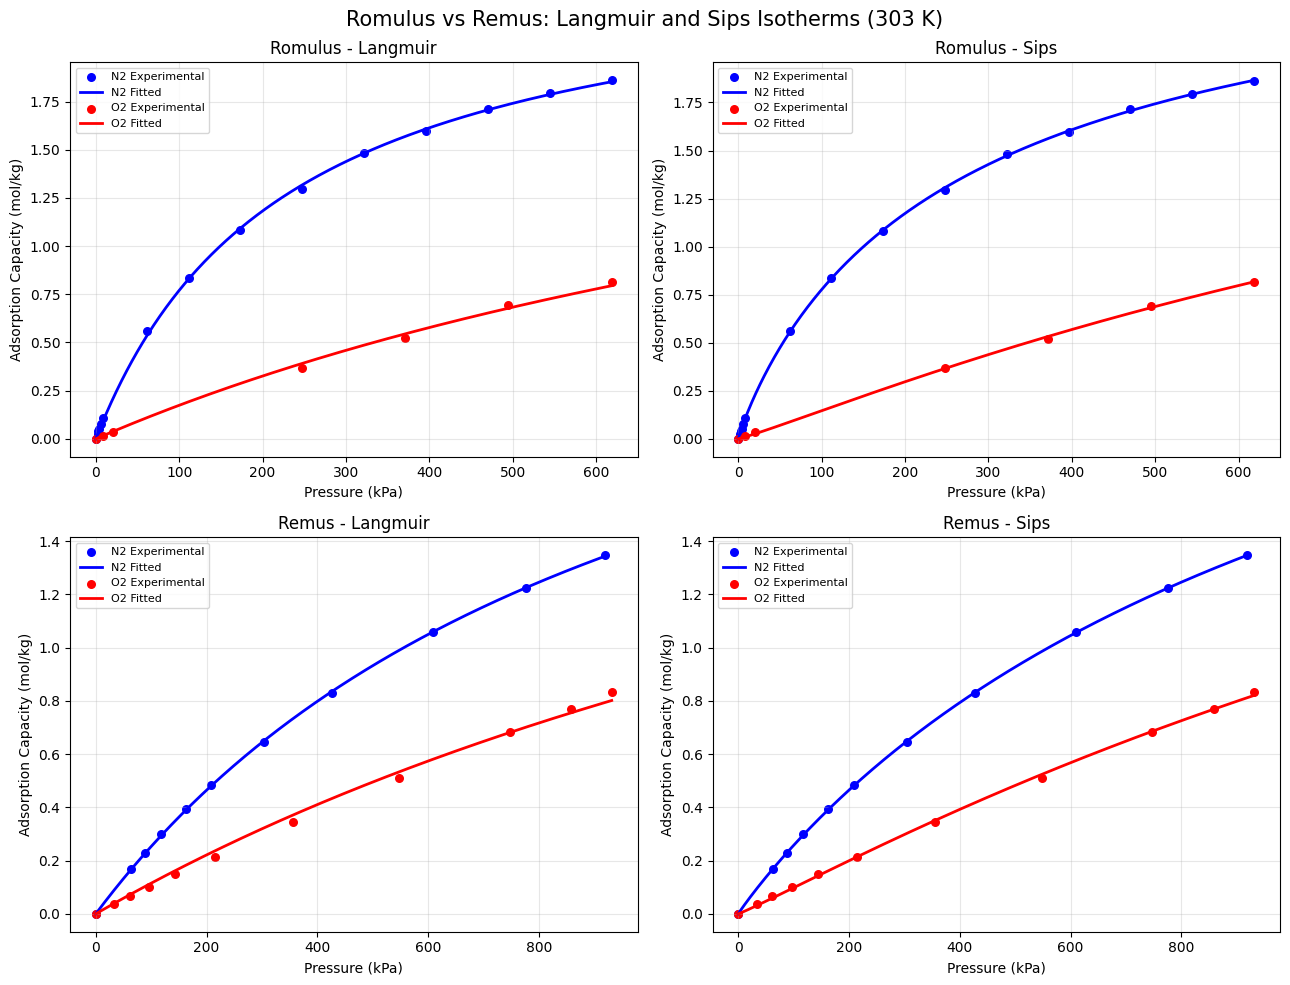

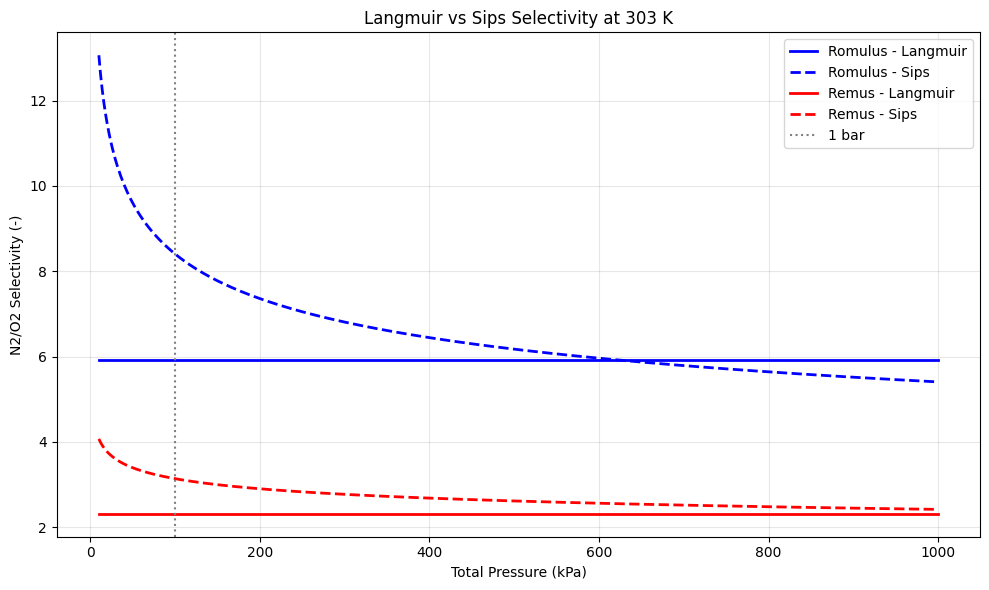

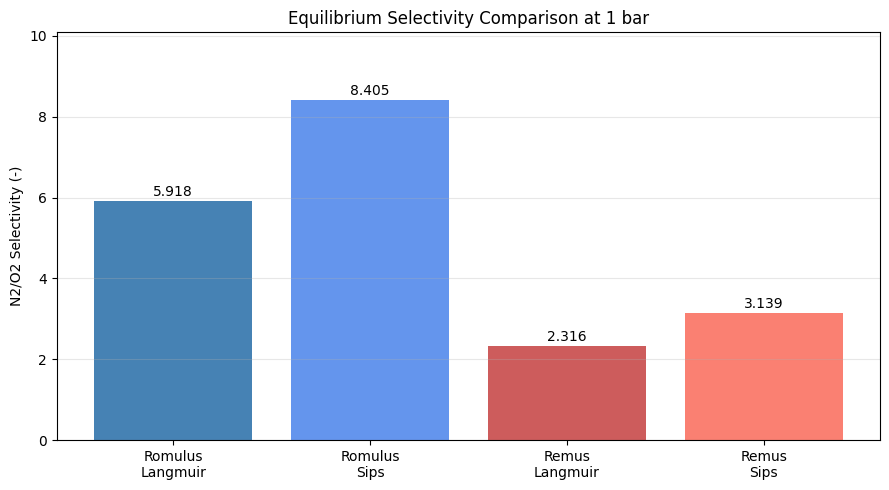


Comparison completed.
Results exported to Romulus_Remus_Comparison.xlsx


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

# ============================================================
# 1. EXPERIMENTAL DATA AT 303 K
# ============================================================

data = {
    "Romulus": {
        "N2": {
            "P": np.array([
                0, 2026.5, 3039.75, 4053, 6079.5,
                8106, 61909.575, 111356.175, 173265.75,
                247435.65, 321706.875, 395978.10,
                470148, 544419.225, 618690.45
            ]),
            "q": np.array([
                0, 0.025, 0.038, 0.053, 0.079,
                0.108, 0.562, 0.835, 1.082,
                1.295, 1.482, 1.597, 1.714,
                1.795, 1.861
            ])
        },
        "O2": {
            "P": np.array([
                0, 8106, 20265, 247435.65,
                371153.475, 494871.3, 618690.45
            ]),
            "q": np.array([
                0, 0.015, 0.035, 0.366,
                0.521, 0.693, 0.815
            ])
        }
    },

    "Remus": {
        "N2": {
            "P": np.array([
                0, 63400, 88700, 117500, 162500,
                208500, 303800, 427000, 609500,
                776600, 919000
            ]),
            "q": np.array([
                0, 0.1674, 0.2300, 0.2994,
                0.3934, 0.4848, 0.6450, 0.8280,
                1.0588, 1.2249, 1.3472
            ])
        },
        "O2": {
            "P": np.array([
                0, 33200, 61300, 96100, 143200,
                214800, 355900, 548200, 747900,
                859000, 931700
            ]),
            "q": np.array([
                0, 0.0372, 0.0679, 0.1022,
                0.1504, 0.2138, 0.3455, 0.5089,
                0.6830, 0.7679, 0.8348
            ])
        }
    }
}

# ============================================================
# 2. ISOTHERM MODELS
# ============================================================

# Use scaled pressure for stable optimization.
# Physical pressure P remains in Pa.
P_REF = 100000.0

def langmuir(P, qs, A):
    term = A * (P / P_REF)
    return qs * term / (1 + term)


def sips(P, qs, A, m):
    term = A * (P / P_REF)**(1 / m)
    return qs * term / (1 + term)


def metrics(q_exp, q_pred):
    sse = np.sum((q_exp - q_pred)**2)
    sst = np.sum((q_exp - np.mean(q_exp))**2)

    r2 = 1 - sse / sst
    rmse = np.sqrt(np.mean((q_exp - q_pred)**2))

    return r2, rmse


# ============================================================
# 3. FITTING FUNCTIONS
# ============================================================

def fit_adsorbent(adsorbent, model):

    P_N2 = data[adsorbent]["N2"]["P"]
    q_N2 = data[adsorbent]["N2"]["q"]

    P_O2 = data[adsorbent]["O2"]["P"]
    q_O2 = data[adsorbent]["O2"]["q"]

    if model == "Langmuir":

        # Fit N2: qs and A_N2
        result_N2 = least_squares(
            lambda x: langmuir(P_N2, x[0], x[1]) - q_N2,
            x0=[2.8, 0.2],
            bounds=([0, 1e-12], [np.inf, np.inf]),
            max_nfev=100000,
            xtol=1e-12,
            ftol=1e-12,
            gtol=1e-12
        )

        qs, A_N2 = result_N2.x
        m_N2 = 1.0

        # Fit O2: fixed qs
        result_O2 = least_squares(
            lambda x: langmuir(P_O2, qs, x[0]) - q_O2,
            x0=[0.05],
            bounds=([1e-12], [np.inf]),
            max_nfev=100000,
            xtol=1e-12,
            ftol=1e-12,
            gtol=1e-12
        )

        A_O2 = result_O2.x[0]
        m_O2 = 1.0

    elif model == "Sips":

        # Fit N2: qs, A_N2, m_N2
        result_N2 = least_squares(
            lambda x: sips(P_N2, x[0], x[1], x[2]) - q_N2,
            x0=[2.8, 0.2, 1.0],
            bounds=(
                [0, 1e-12, 0.1],
                [np.inf, np.inf, 10]
            ),
            max_nfev=100000,
            xtol=1e-12,
            ftol=1e-12,
            gtol=1e-12
        )

        qs, A_N2, m_N2 = result_N2.x

        # Fit O2: fixed qs, optimize A_O2 and m_O2
        result_O2 = least_squares(
            lambda x: sips(P_O2, qs, x[0], x[1]) - q_O2,
            x0=[0.05, 1.0],
            bounds=(
                [1e-12, 0.1],
                [np.inf, 10]
            ),
            max_nfev=100000,
            xtol=1e-12,
            ftol=1e-12,
            gtol=1e-12
        )

        A_O2, m_O2 = result_O2.x

    else:
        raise ValueError("Unknown model")

    # Convert affinity constants to Pa-based units
    K_N2 = A_N2 / P_REF**(1 / m_N2)
    K_O2 = A_O2 / P_REF**(1 / m_O2)

    # Predictions
    if model == "Langmuir":
        q_pred_N2 = langmuir(P_N2, qs, A_N2)
        q_pred_O2 = langmuir(P_O2, qs, A_O2)
    else:
        q_pred_N2 = sips(P_N2, qs, A_N2, m_N2)
        q_pred_O2 = sips(P_O2, qs, A_O2, m_O2)

    r2_N2, rmse_N2 = metrics(q_N2, q_pred_N2)
    r2_O2, rmse_O2 = metrics(q_O2, q_pred_O2)

    return {
        "qs": qs,
        "A_N2": A_N2,
        "K_N2": K_N2,
        "m_N2": m_N2,
        "A_O2": A_O2,
        "K_O2": K_O2,
        "m_O2": m_O2,
        "R2_N2": r2_N2,
        "RMSE_N2": rmse_N2,
        "R2_O2": r2_O2,
        "RMSE_O2": rmse_O2
    }


# ============================================================
# 4. FIT ALL MODELS
# ============================================================

results = {}

for adsorbent in ["Romulus", "Remus"]:
    for model in ["Langmuir", "Sips"]:
        results[(adsorbent, model)] = fit_adsorbent(
            adsorbent, model
        )


# ============================================================
# 5. PARAMETER AND FITTING COMPARISON TABLE
# ============================================================

rows = []

for (adsorbent, model), r in results.items():

    for gas in ["N2", "O2"]:

        rows.append({
            "Adsorbent": adsorbent,
            "Model": model,
            "Gas": gas,
            "qs (mol/kg)": r["qs"],
            "K (Pa^(-1/m))": r[f"K_{gas}"],
            "m": r[f"m_{gas}"],
            "R2": r[f"R2_{gas}"],
            "RMSE (mol/kg)": r[f"RMSE_{gas}"]
        })

comparison_df = pd.DataFrame(rows)

print("\nISOTHERM PARAMETER AND FITTING COMPARISON")
print("=" * 80)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6g}"
    )
)

# ============================================================
# 6. SELECTIVITY CALCULATION
# ============================================================

# Binary air composition
y_N2 = 0.79
y_O2 = 0.21

def calculate_selectivity(P_total, r):

    P_N2 = y_N2 * P_total
    P_O2 = y_O2 * P_total

    term_N2 = (
        r["K_N2"] *
        P_N2**(1 / r["m_N2"])
    )

    term_O2 = (
        r["K_O2"] *
        P_O2**(1 / r["m_O2"])
    )

    # Extended competitive Langmuir/Sips assumption
    return (
        (term_N2 / term_O2)
        * (y_O2 / y_N2)
    )


P_operating = 100000.0  # 1 bar, Pa

selectivity_rows = []

for (adsorbent, model), r in results.items():

    S = calculate_selectivity(P_operating, r)

    selectivity_rows.append({
        "Adsorbent": adsorbent,
        "Model": model,
        "N2/O2 Selectivity at 1 bar": S
    })

selectivity_df = pd.DataFrame(selectivity_rows)

print("\nSELECTIVITY COMPARISON AT 1 BAR")
print("=" * 60)

print(
    selectivity_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ============================================================
# 7. PLOT A: EXPERIMENTAL VS FITTED ISOTHERMS
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10),
    sharex=False
)

for i, adsorbent in enumerate(["Romulus", "Remus"]):

    for j, model in enumerate(["Langmuir", "Sips"]):

        ax = axes[i, j]
        r = results[(adsorbent, model)]

        for gas, color in [("N2", "blue"), ("O2", "red")]:

            P_exp = data[adsorbent][gas]["P"]
            q_exp = data[adsorbent][gas]["q"]

            P_smooth = np.linspace(
                0, max(P_exp), 500
            )

            A = r[f"A_{gas}"]
            m = r[f"m_{gas}"]

            if model == "Langmuir":
                q_smooth = langmuir(
                    P_smooth, r["qs"], A
                )
            else:
                q_smooth = sips(
                    P_smooth, r["qs"], A, m
                )

            ax.scatter(
                P_exp / 1000,
                q_exp,
                color=color,
                s=30,
                label=f"{gas} Experimental"
            )

            ax.plot(
                P_smooth / 1000,
                q_smooth,
                color=color,
                linewidth=2,
                label=f"{gas} Fitted"
            )

        ax.set_title(f"{adsorbent} - {model}")
        ax.set_xlabel("Pressure (kPa)")
        ax.set_ylabel("Adsorption Capacity (mol/kg)")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)

plt.suptitle(
    "Romulus vs Remus: Langmuir and Sips Isotherms (303 K)",
    fontsize=15
)

plt.tight_layout()
plt.savefig("Isotherm_Comparison.png", dpi=300)
plt.show()


# ============================================================
# 8. PLOT B: N2/O2 SELECTIVITY VS PRESSURE
# ============================================================

P_range = np.linspace(10000, 1000000, 500)

plt.figure(figsize=(10, 6))

styles = {
    ("Romulus", "Langmuir"): ("blue", "-"),
    ("Romulus", "Sips"): ("blue", "--"),
    ("Remus", "Langmuir"): ("red", "-"),
    ("Remus", "Sips"): ("red", "--")
}

for key, r in results.items():

    color, linestyle = styles[key]

    S = calculate_selectivity(P_range, r)

    plt.plot(
        P_range / 1000,
        S,
        color=color,
        linestyle=linestyle,
        linewidth=2,
        label=f"{key[0]} - {key[1]}"
    )

plt.axvline(
    100,
    color="gray",
    linestyle=":",
    label="1 bar"
)

plt.xlabel("Total Pressure (kPa)")
plt.ylabel("N2/O2 Selectivity (-)")
plt.title("Langmuir vs Sips Selectivity at 303 K")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("Selectivity_Comparison.png", dpi=300)
plt.show()


# ============================================================
# 9. PLOT C: SELECTIVITY COMPARISON AT 1 BAR
# ============================================================

labels = [
    f"{row['Adsorbent']}\n{row['Model']}"
    for row in selectivity_rows
]

values = [
    row["N2/O2 Selectivity at 1 bar"]
    for row in selectivity_rows
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    labels,
    values,
    color=["steelblue", "cornflowerblue",
           "indianred", "salmon"]
)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + max(values) * 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.ylabel("N2/O2 Selectivity (-)")
plt.title("Equilibrium Selectivity Comparison at 1 bar")
plt.ylim(0, max(values) * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("Selectivity_Bar_Chart.png", dpi=300)
plt.show()


# ============================================================
# 10. EXPORT RESULTS TO EXCEL
# ============================================================

with pd.ExcelWriter(
    "Romulus_Remus_Comparison.xlsx",
    engine="openpyxl"
) as writer:

    comparison_df.to_excel(
        writer,
        sheet_name="Fitting Parameters",
        index=False
    )

    selectivity_df.to_excel(
        writer,
        sheet_name="Selectivity",
        index=False
    )

print("\nComparison completed.")
print("Results exported to Romulus_Remus_Comparison.xlsx")
